# London Energy Forecasting: Phase 1 EDA — Track A
## Historical Evolution & Time Series Analysis (`01_historical_time_series_eda.ipynb`)

> **Document Reference:** Based on the official *London Smart Meter Energy Consumption EDA Handover & Execution Playbook (V1.0, Oct 2026)*  
> **Author Track:** Analyst A (Historical & Time Series EDA)  
> **Input Parquet:** `part-00000-cc27d2b9-c47c-428f-bcfd-3f53458990d4-c000.snappy.parquet` (`eda_hourly_history`)  
> **Dataset Profile:** 19,864 rows × 9 columns | Natural Key: `hour_start` | Period: 2011-11-23 09:00 to 2014-02-28 00:00  

---

### Playbook Execution Contract & Core Questions
This notebook provides a complete, reproducible execution of the **Track A Core Playbook (Analyses A1–A8)**, adhering to the analytical safety rules and reporting standards specified in the Handover Playbook:
1. **Historical Evolution (A1):** How has typical hourly electricity consumption per complete reporting home changed over time?
2. **Year-over-Year Seasonality (A2):** Do corresponding months in 2012 and 2013 show similar typical consumption patterns?
3. **Intraday Profile (A3):** Which recorded hours have the highest typical per-home consumption?
4. **Weekday vs Weekend (A4):** How do the shape and timing of typical hourly consumption differ between weekdays and weekends?
5. **Weekday × Hour Heatmap (A5):** Which combinations of weekday and recorded hour show consistently high consumption?
6. **Seasonal Demand Profile (A6):** Does the timing or amplitude of the usual consumption peak differ between meteorological seasons?
7. **Participation & Coverage Diagnosis (A7):** When do reporting counts or coverage change, potentially distorting trend analysis?
8. **Autocorrelation & Lag Structure (A8):** Does the hourly series display daily (lag 24) or weekly (lag 168) dependence?

### Analytical Safety & Interpretation Guardrails
* **Proper Denominators:** We evaluate consumption using `avg_kwh_per_complete_home` (kWh per complete home-hour) rather than raw totals, since household participation grew from 41 to >5,500 homes.
* **No Causal Overreach:** Weather, property attributes, and occupancy data are not part of the delivered tables; observed shapes reflect associations and behavioral rhythms, not proven causes.
* **Coverage Contract:** Observed-span coverage for aggregations is recomputed from summed numerators and denominators ($\sum \text{observed} / \sum \text{expected} \times 100$), never averaged percentages.
* **Standardized Insight Structure:** Every finding reports: `Question` → `Eligible Population` → `Numeric Evidence` → `Finding` → `Interpretation` → `Limitation`.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from statsmodels.tsa.stattools import acf

# Configure aesthetic theme for publication-grade visualization
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Segoe UI, Helvetica Neue, Arial, sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'semibold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['grid.linestyle'] = '--'

# Curated harmonious color palette
PALETTE = {
    'primary': '#1B365D',     # Deep Navy
    'secondary': '#2B7A78',   # Forest Teal
    'accent': '#D9534F',      # Warm Coral
    'amber': '#E65100',       # Deep Amber
    'purple': '#5E35B1',      # Deep Violet
    'gray': '#607D8B',        # Slate Gray
    'winter': '#1976D2',      # Blue
    'spring': '#388E3C',      # Green
    'summer': '#F57C00',      # Orange
    'autumn': '#D32F2F',      # Red
}

print(f"Environment initialized successfully:")
print(f" - Python: {sys.version.split()[0]}")
print(f" - Pandas: {pd.__version__}")
print(f" - Matplotlib: {plt.matplotlib.__version__}")
print(f" - Seaborn: {sns.__version__}")


Environment initialized successfully:
 - Python: 3.13.16
 - Pandas: 2.2.3
 - Matplotlib: 3.10.0
 - Seaborn: 0.13.2


In [2]:
# Load validated Track A Parquet dataset via project-relative path
DATA_PATH = "part-00000-cc27d2b9-c47c-428f-bcfd-3f53458990d4-c000.snappy.parquet"
df = pd.read_parquet(DATA_PATH)

# Verify dataset dimensions and schema contracts (Playbook Section 04 & 05)
expected_cols = [
    'hour_start', 'energy_kwh_observed', 'energy_kwh_complete_homes',
    'homes_reporting', 'homes_complete', 'readings_observed',
    'readings_expected_in_span', 'coverage_pct_in_span', 'avg_kwh_per_complete_home'
]
assert list(df.columns) == expected_cols, f"Column mismatch! Found {list(df.columns)}"
assert len(df) == 19864, f"Row count mismatch! Expected 19864, found {len(df)}"

# Sort chronologically by hour_start
df = df.sort_values('hour_start').reset_index(drop=True)

# Verify 1-hour time continuity
t_min, t_max = df['hour_start'].min(), df['hour_start'].max()
expected_range = pd.date_range(t_min, t_max, freq='h')
missing_hours = expected_range.difference(df['hour_start'])
assert len(missing_hours) == 0, f"Discovered {len(missing_hours)} missing hours in range!"

# Inspect data contract edge case: avg_kwh_per_complete_home nulls
null_mask = df['avg_kwh_per_complete_home'].isna()
null_rows = df[null_mask]

print("=== DATA CONTRACT VALIDATION REPORT ===")
print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Time Range: {t_min} to {t_max} (1-hour uniform continuous grid)")
print(f"Total Span: {len(expected_range):,} expected hours | Missing Grid Hours: {len(missing_hours)}")
print(f"Null Count in avg_kwh_per_complete_home: {null_mask.sum()}")
if len(null_rows) > 0:
    for idx, r in null_rows.iterrows():
        print(f" -> Null Row #{idx}: hour_start={r['hour_start']}, homes_reporting={r['homes_reporting']}, "
              f"homes_complete={r['homes_complete']}, energy_complete={r['energy_kwh_complete_homes']}")
        print(f"    Explanation: At dataset cut-off (2014-02-28 00:00), only 1 reading exists per home; "
              f"hence homes_complete=0, leading to 0.0/0 = NaN as documented in Playbook Section 05.")


=== DATA CONTRACT VALIDATION REPORT ===
Dataset Shape: 19,864 rows × 9 columns
Time Range: 2011-11-23 09:00:00 to 2014-02-28 00:00:00 (1-hour uniform continuous grid)
Total Span: 19,864 expected hours | Missing Grid Hours: 0
Null Count in avg_kwh_per_complete_home: 1
 -> Null Row #19863: hour_start=2014-02-28 00:00:00, homes_reporting=4987, homes_complete=0, energy_complete=0.0
    Explanation: At dataset cut-off (2014-02-28 00:00), only 1 reading exists per home; hence homes_complete=0, leading to 0.0/0 = NaN as documented in Playbook Section 05.


In [17]:
df.columns

Index(['hour_start', 'energy_kwh_observed', 'energy_kwh_complete_homes',
       'homes_reporting', 'homes_complete', 'readings_observed',
       'readings_expected_in_span', 'coverage_pct_in_span',
       'avg_kwh_per_complete_home', 'year', 'month', 'year_month', 'day',
       'hour', 'day_name', 'dayofweek', 'is_weekend', 'season'],
      dtype='object')

In [15]:
df.sample(10)

,hour_start,energy_kwh_observed,energy_kwh_complete_homes,homes_reporting,homes_complete,readings_observed,readings_expected_in_span,coverage_pct_in_span,avg_kwh_per_complete_home,year,month,year_month,day,hour,day_name,dayofweek,is_weekend,season
18896,2014-01-18 17:00:00,3455.024000,3428.240000,5067,5000,10067,10158,99.1042,0.685648,2014,1,2014-01,18,17,Saturday,5,True,Winter
17225,2013-11-10 02:00:00,1375.271000,1375.271000,5180,5180,10360,10382,99.7881,0.265496,2013,11,2013-11,10,2,Sunday,6,True,Autumn
15761,2013-09-10 02:00:00,1025.040001,1025.040001,5235,5235,10470,10488,99.8284,0.195805,2013,9,2013-09,10,2,Tuesday,1,False,Autumn
550,2011-12-16 07:00:00,120.116000,120.116000,252,252,504,504,100.0000,0.476651,2011,12,2011-12,16,7,Friday,4,False,Winter
274,2011-12-04 19:00:00,83.508000,83.508000,110,110,220,220,100.0000,0.759164,2011,12,2011-12,4,19,Sunday,6,True,Winter
1669,2012-01-31 22:00:00,429.101000,429.101000,581,581,1162,1162,100.0000,0.738556,2012,1,2012-01,31,22,Tuesday,1,False,Winter
15141,2013-08-15 06:00:00,1497.188000,1497.188000,5274,5274,10548,10568,99.8107,0.283881,2013,8,2013-08,15,6,Thursday,3,False,Summer
8377,2012-11-06 10:00:00,2446.224000,2446.224000,5519,5519,11038,11050,99.8914,0.443237,2012,11,2012-11,6,10,Tuesday,1,False,Autumn
10428,2013-01-30 21:00:00,3857.323999,3857.006999,5485,5484,10969,10982,99.8816,0.703320,2013,1,2013-01,30,21,Wednesday,2,False,Winter
12523,2013-04-28 04:00:00,1165.019000,1165.019000,5378,5378,10756,10774,99.8329,0.216627,2013,4,2013-04,28,4,Sunday,6,True,Spring


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19864 entries, 0 to 19863
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   hour_start                 19864 non-null  datetime64[us]
 1   energy_kwh_observed        19864 non-null  float64       
 2   energy_kwh_complete_homes  19864 non-null  float64       
 3   homes_reporting            19864 non-null  int64         
 4   homes_complete             19864 non-null  int64         
 5   readings_observed          19864 non-null  int64         
 6   readings_expected_in_span  19864 non-null  int64         
 7   coverage_pct_in_span       19864 non-null  float64       
 8   avg_kwh_per_complete_home  19863 non-null  float64       
 9   year                       19864 non-null  int32         
 10  month                      19864 non-null  int32         
 11  year_month                 19864 non-null  object        
 12  day 

In [18]:
df.nunique()

,0
hour_start,19864
energy_kwh_observed,19862
energy_kwh_complete_homes,19861
homes_reporting,1924
homes_complete,2075
readings_observed,2813
readings_expected_in_span,1946
coverage_pct_in_span,2316
avg_kwh_per_complete_home,19863
year,4


In [19]:
# Check Null (Missing Values)
df.isna().sum()

,0
hour_start,0
energy_kwh_observed,0
energy_kwh_complete_homes,0
homes_reporting,0
homes_complete,0
readings_observed,0
readings_expected_in_span,0
coverage_pct_in_span,0
avg_kwh_per_complete_home,1
year,0


In [3]:
# Derive calendar analysis variables (Playbook Section 07)
# Note: These are derived analytical features, preserving original parquet contract
df['year'] = df['hour_start'].dt.year
df['month'] = df['hour_start'].dt.month
df['year_month'] = df['hour_start'].dt.to_period('M').astype(str)
df['day'] = df['hour_start'].dt.day
df['hour'] = df['hour_start'].dt.hour
df['day_name'] = df['hour_start'].dt.day_name()
df['dayofweek'] = df['hour_start'].dt.dayofweek # 0=Monday, 6=Sunday
df['is_weekend'] = df['dayofweek'] >= 5

# Define fixed meteorological seasons:
# Winter (Dec, Jan, Feb), Spring (Mar, Apr, May), Summer (Jun, Jul, Aug), Autumn (Sep, Oct, Nov)
def get_meteorological_season(m):
    if m in [12, 1, 2]:
        return 'Winter'
    elif m in [3, 4, 5]:
        return 'Spring'
    elif m in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['season'] = df['month'].apply(get_meteorological_season)
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
df['season'] = pd.Categorical(df['season'], categories=season_order, ordered=True)

print("Calendar Variables Engineered:")
print(f" - Distinct year-months: {df['year_month'].nunique()} ({df['year_month'].min()} to {df['year_month'].max()})")
print(f" - Weekdays: Mon-Fri = {(~df['is_weekend']).sum():,} hours | Weekends: Sat-Sun = {df['is_weekend'].sum():,} hours")
print(f" - Seasonal distribution (hours):")
print(df['season'].value_counts()[season_order].to_string())


Calendar Variables Engineered:
 - Distinct year-months: 28 (2011-11 to 2014-02)
 - Weekdays: Mon-Fri = 14,200 hours | Weekends: Sat-Sun = 5,664 hours
 - Seasonal distribution (hours):
season
Winter    6481
Spring    4416
Summer    4416
Autumn    4551


---
## Section 1: A7 — Participation and Span Coverage Diagnosis

### Business Question
> **When do reporting home counts or observed-span coverage change, and might this distort trend analysis?**

### Playbook Method & Aggregation Contract
* **Aggregation Rule (Playbook p.13):** Monthly observed-span coverage must be recomputed from summed numerators and denominators ($\frac{\sum \text{readings\_observed}}{\sum \text{readings\_expected\_in\_span}} \times 100$), never by taking the arithmetic mean of hourly percentages.
* **Participation Metrics:** Track monthly median of `homes_reporting` and `homes_complete`.
* **Analytical Safety:** Understand the sample composition shifts before interpreting energy trend levels.


=== MONTHLY PARTICIPATION AND COVERAGE AUDIT ===
year_month  hours_count  median_reporting  median_complete  coverage_pct
   2011-11          183              41.0             41.0     99.979844
   2011-12          744             261.5            260.0     99.895592
   2012-01          744             443.5            441.5     99.906437
   2012-02          696             719.5            719.0     99.926760
   2012-03          744            1024.0           1021.0     99.931309
   2012-04          720            1498.0           1498.0     99.848585
   2012-05          744            2836.0           2807.0     99.511862
   2012-06          720            3942.0           3940.0     97.705962
   2012-07          744            4736.0           4735.0     99.774381
   2012-08          744            4757.0           4757.0     99.876712
   2012-09          720            4800.0           4800.0     99.901629
   2012-10          744            5289.5           5280.0     99.904966
  

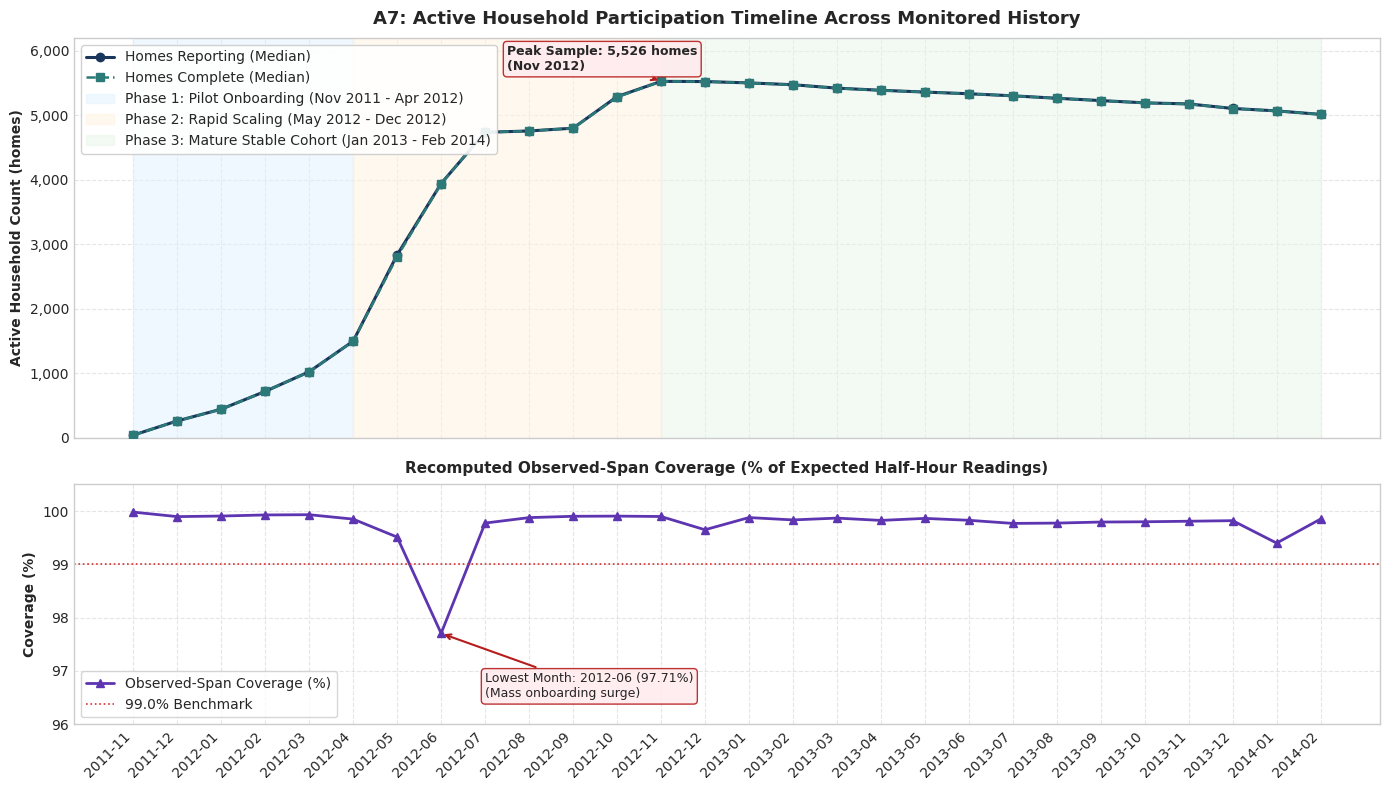

In [4]:
# A7: Aggregate monthly participation and recomputed span coverage
a7_monthly = df.groupby('year_month').agg(
    hours_count=('hour_start', 'count'),
    median_reporting=('homes_reporting', 'median'),
    median_complete=('homes_complete', 'median'),
    sum_readings_obs=('readings_observed', 'sum'),
    sum_readings_exp=('readings_expected_in_span', 'sum')
).reset_index()

# Recompute monthly coverage percentage
a7_monthly['coverage_pct'] = 100.0 * a7_monthly['sum_readings_obs'] / a7_monthly['sum_readings_exp']

# Display summary table
print("=== MONTHLY PARTICIPATION AND COVERAGE AUDIT ===")
display_cols = ['year_month', 'hours_count', 'median_reporting', 'median_complete', 'coverage_pct']
print(a7_monthly[display_cols].to_string(index=False))

# Visualization: 2-Panel Participation & Coverage Audit
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})

x_idx = np.arange(len(a7_monthly))
x_labels = a7_monthly['year_month'].values

# Panel 1: Household Participation Timeline
ax1.plot(x_idx, a7_monthly['median_reporting'], color=PALETTE['primary'], marker='o',
         linewidth=2.2, label='Homes Reporting (Median)', zorder=3)
ax1.plot(x_idx, a7_monthly['median_complete'], color=PALETTE['secondary'], marker='s',
         linestyle='--', linewidth=1.8, label='Homes Complete (Median)', zorder=3)

# Highlight project roll-out phases
ax1.axvspan(0, 5, color='#E0F2FE', alpha=0.5, label='Phase 1: Pilot Onboarding (Nov 2011 - Apr 2012)')
ax1.axvspan(5, 12, color='#FFF3E0', alpha=0.5, label='Phase 2: Rapid Scaling (May 2012 - Dec 2012)')
ax1.axvspan(12, 27, color='#E8F5E9', alpha=0.5, label='Phase 3: Mature Stable Cohort (Jan 2013 - Feb 2014)')

ax1.set_title('A7: Active Household Participation Timeline Across Monitored History', fontsize=13, pad=10)
ax1.set_ylabel('Active Household Count (homes)')
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax1.legend(loc='upper left', frameon=True, framealpha=0.9)
ax1.set_ylim(0, 6200)

# Add key annotation
ax1.annotate('Peak Sample: 5,526 homes\n(Nov 2012)', xy=(12, 5526), xytext=(8.5, 5700),
             arrowprops=dict(arrowstyle='->', color='#B71C1C', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFEBEE', edgecolor='#B71C1C', alpha=0.9),
             fontweight='bold', fontsize=9)

# Panel 2: Observed-Span Coverage (%)
ax2.plot(x_idx, a7_monthly['coverage_pct'], color=PALETTE['purple'], marker='^', linewidth=2, label='Observed-Span Coverage (%)')
ax2.axhline(99.0, color='#D32F2F', linestyle=':', linewidth=1.2, label='99.0% Benchmark')

# Annotate June 2012 dip
min_cov_idx = a7_monthly['coverage_pct'].idxmin()
min_cov_val = a7_monthly.loc[min_cov_idx, 'coverage_pct']
min_cov_month = a7_monthly.loc[min_cov_idx, 'year_month']
ax2.annotate(f'Lowest Month: {min_cov_month} ({min_cov_val:.2f}%)\n(Mass onboarding surge)',
             xy=(min_cov_idx, min_cov_val), xytext=(min_cov_idx + 1, min_cov_val - 1.2),
             arrowprops=dict(arrowstyle='->', color='#B71C1C', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFEBEE', edgecolor='#B71C1C', alpha=0.9),
             fontsize=9)

ax2.set_title('Recomputed Observed-Span Coverage (% of Expected Half-Hour Readings)', fontsize=11, pad=8)
ax2.set_ylabel('Coverage (%)')
ax2.set_xticks(x_idx)
ax2.set_xticklabels(x_labels, rotation=45, ha='right')
ax2.set_ylim(96.0, 100.5)
ax2.legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()


---
## Section 2: A1 — Historical Energy Trend

### Business Question
> **How has typical hourly electricity consumption per complete reporting home changed across the recorded history?**

### Playbook Method & Guardrail
* **Primary Metric (Playbook p.10):** Monthly median of `avg_kwh_per_complete_home`.



=== A1: HISTORICAL ENERGY TREND SUMMARY ===
year_month  median_kwh  q25_kwh  q75_kwh  median_complete_homes
   2011-11      0.4019   0.3399   0.5356                   41.0
   2011-12      0.5043   0.3783   0.6361                  260.0
   2012-01      0.5149   0.4385   0.6524                  441.5
   2012-02      0.5410   0.4635   0.6404                  719.0
   2012-03      0.4532   0.3709   0.5420                 1021.0
   2012-04      0.4251   0.3668   0.4991                 1498.0
   2012-05      0.3751   0.3087   0.4483                 2807.0
   2012-06      0.3632   0.2712   0.4312                 3940.0
   2012-07      0.3510   0.2687   0.4141                 4735.0
   2012-08      0.3400   0.2659   0.3956                 4757.0
   2012-09      0.3560   0.2678   0.4310                 4800.0
   2012-10      0.4122   0.3069   0.5112                 5280.0
   2012-11      0.4600   0.3443   0.5933                 5526.0
   2012-12      0.5260   0.3707   0.6390                 552

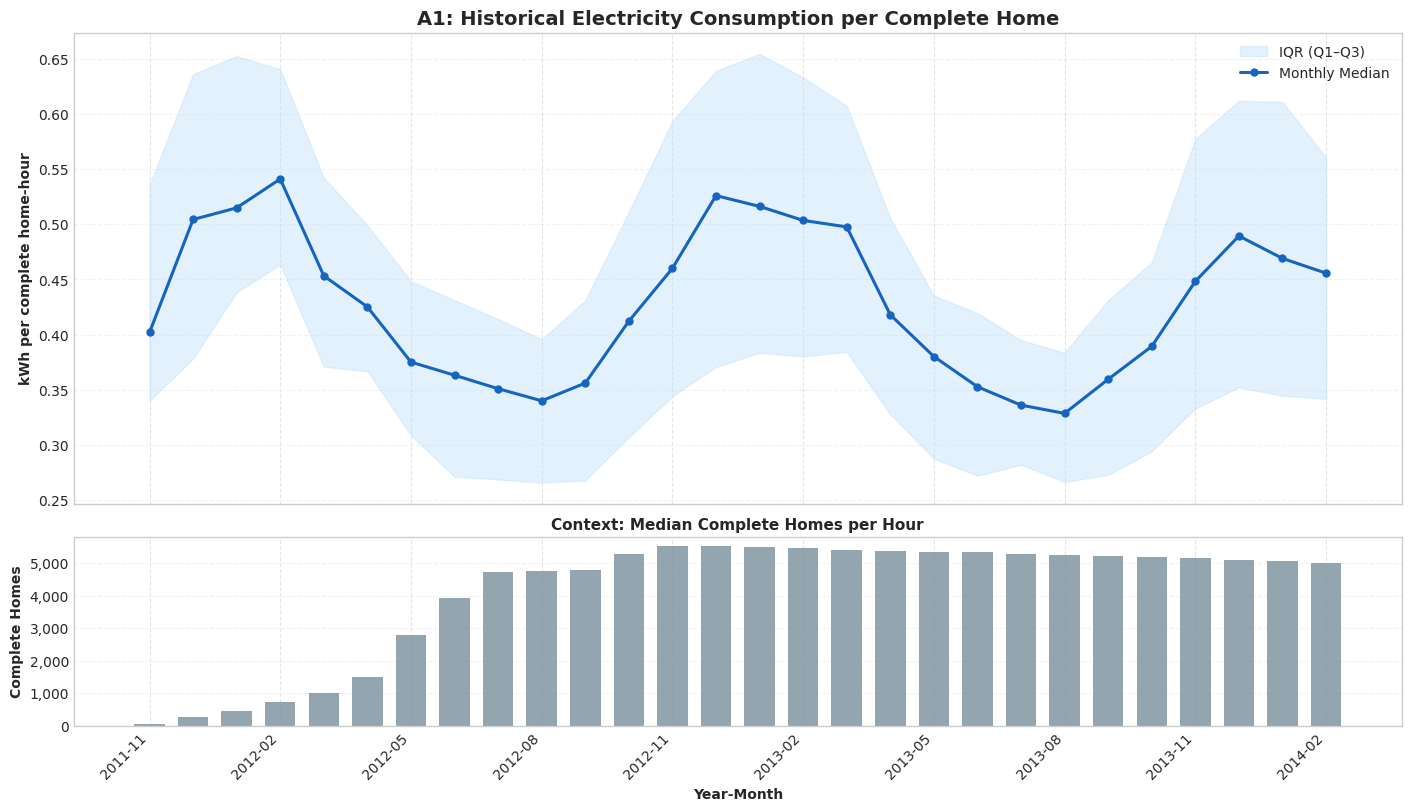

In [5]:
# ============================================================
# A1 — Historical Energy Trend
# ============================================================

# 1. Monthly aggregation
a1_monthly = (
    df.groupby('year_month')
    .agg(
        median_kwh=('avg_kwh_per_complete_home', 'median'),
        q25_kwh=('avg_kwh_per_complete_home', lambda x: x.quantile(0.25)),
        q75_kwh=('avg_kwh_per_complete_home', lambda x: x.quantile(0.75)),
        median_complete_homes=('homes_complete', 'median')
    )
    .reset_index()
    .sort_values('year_month')
    .reset_index(drop=True)
)

# 2. Display monthly results
print("=== A1: HISTORICAL ENERGY TREND SUMMARY ===")

display_cols = [
    'year_month',
    'median_kwh',
    'q25_kwh',
    'q75_kwh',
    'median_complete_homes'
]

print(a1_monthly[display_cols].round(4).to_string(index=False))

# 3. Highest and lowest monthly medians
peak = a1_monthly.loc[a1_monthly['median_kwh'].idxmax()]
trough = a1_monthly.loc[a1_monthly['median_kwh'].idxmin()]

print("\n=== KEY FINDINGS ===")
print(f"Highest monthly median: {peak['year_month']} "
      f"({peak['median_kwh']:.4f} kWh/home-hour)")

print(f"Lowest monthly median: {trough['year_month']} "
      f"({trough['median_kwh']:.4f} kWh/home-hour)")


# ============================================================
# 4. Visualization
# ============================================================

x = np.arange(len(a1_monthly))

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True,
    gridspec_kw={'height_ratios': [2.5, 1]},
    constrained_layout=True
)

# Panel 1: Monthly Median and IQR
ax1.fill_between(
    x,
    a1_monthly['q25_kwh'].to_numpy(),
    a1_monthly['q75_kwh'].to_numpy(),
    color='#BBDEFB',
    alpha=0.4,
    label='IQR (Q1–Q3)'
)

ax1.plot(
    x,
    a1_monthly['median_kwh'],
    color='#1565C0',
    marker='o',
    markersize=5,
    linewidth=2.2,
    label='Monthly Median'
)

ax1.set_title(
    'A1: Historical Electricity Consumption per Complete Home',
    fontsize=14,
    fontweight='bold'
)
ax1.set_ylabel('kWh per complete home-hour')
ax1.grid(axis='y', alpha=0.25)
ax1.legend(loc='best')

# Panel 2: Participation context
ax2.bar(
    x,
    a1_monthly['median_complete_homes'],
    color='#78909C',
    alpha=0.8,
    width=0.7
)

ax2.set_title('Context: Median Complete Homes per Hour', fontsize=11)
ax2.set_ylabel('Complete Homes')
ax2.grid(axis='y', alpha=0.25)
ax2.yaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

# X-axis: every 3 months plus final month
tick_idx = np.unique(
    np.r_[np.arange(0, len(a1_monthly), 3), len(a1_monthly) - 1]
)

ax2.set_xticks(tick_idx)
ax2.set_xticklabels(
    a1_monthly.loc[tick_idx, 'year_month'],
    rotation=45,
    ha='right'
)
ax2.set_xlabel('Year-Month')

plt.show()

---
## Section 3: A2 — Year-over-Year Seasonality (2012 vs 2013)

### Business Question
> **Do corresponding months in 2012 and 2013 exhibit similar typical consumption patterns?**

### Playbook Method & Guardrail
* **Analysis Window (Playbook p.10):** Full calendar years 2012 vs 2013 (January to December).
* **Metric:** Monthly median of `avg_kwh_per_complete_home` for matching months.
* **Evidence Required:** Absolute differences (kWh), percentage differences (%), and sample size context.
* **Guardrail:** 2012 is a leap year (29 days / 696 hours in February vs 28 days / 672 hours in 2013). Household cohort size also differed substantially; never compare unadjusted annual gross totals.


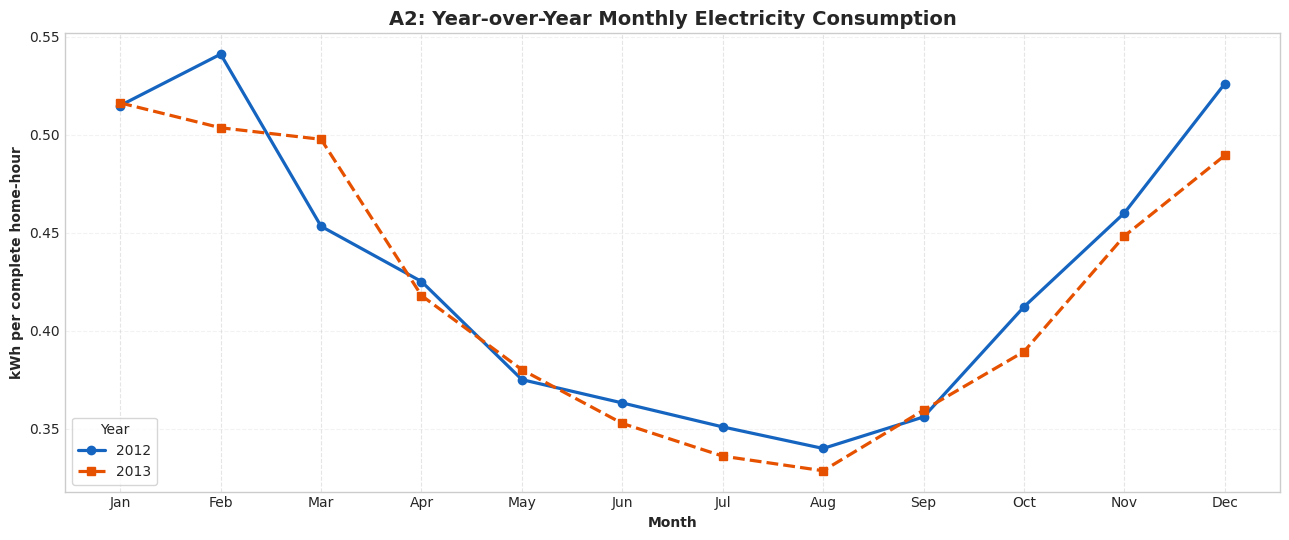

In [14]:
# ============================================================
# A2 — Year-over-Year Comparison (2012 vs 2013)
# Single Line Plot with Month Names
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Filter the two complete calendar years
df_12_13 = df[df['year'].isin([2012, 2013])].copy()

# 2. Monthly aggregation
a2_monthly = (
    df_12_13.groupby(['year', 'month'])
    .agg(
        median_kwh=('avg_kwh_per_complete_home', 'median')
    )
    .reset_index()
)

# 3. Pivot to place 2012 and 2013 side by side
a2_pivot = (
    a2_monthly.pivot(
        index='month',
        columns='year',
        values='median_kwh'
    )
    .reindex(index=range(1, 13), columns=[2012, 2013])
)

a2_pivot.columns = ['kwh_2012', 'kwh_2013']

# 4. Add month names
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

a2_pivot['month_name'] = month_names

# Optional validation
assert a2_pivot[['kwh_2012', 'kwh_2013']].notna().all().all()

# ============================================================
# 5. Visualization — line plot only
# ============================================================

plt.figure(figsize=(13, 5.5))

plt.plot(
    a2_pivot['month_name'],
    a2_pivot['kwh_2012'],
    color='#1565C0',
    marker='o',
    linewidth=2.3,
    markersize=6,
    label='2012'
)

plt.plot(
    a2_pivot['month_name'],
    a2_pivot['kwh_2013'],
    color='#E65100',
    marker='s',
    linestyle='--',
    linewidth=2.3,
    markersize=6,
    label='2013'
)

plt.title(
    'A2: Year-over-Year Monthly Electricity Consumption',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Month')
plt.ylabel('kWh per complete home-hour')
plt.grid(axis='y', alpha=0.25)
plt.legend(title='Year', frameon=True)

plt.tight_layout()
plt.show()

---
## Section 4: A3 — Intraday Consumption Profile

### Business Question
> **Which recorded hours have the highest typical energy consumption per complete reporting household?**

### Playbook Method & Guardrail
* **Analysis Period (Playbook p.11):** All 19,863 eligible recorded hours across the dataset.
* **Primary Metric:** Median hourly per-home kWh by recorded hour-of-day (0–23).
* **Dispersion Metrics:** Interquartile range (IQR: Q1–Q3) band and 5th–95th percentile envelope.
* **Guardrail:** Hours are interpreted strictly as clock hours stored in the dataset; avoid asserting unsupported lifestyle causes without occupancy data.


=== A3: INTRADAY CONSUMPTION PROFILE ===
 hour  median    q25    q75    iqr  count
    0  0.3690 0.2713 0.4495 0.1782    827
    1  0.3133 0.2312 0.3668 0.1356    827
    2  0.2626 0.2078 0.3028 0.0950    827
    3  0.2391 0.1983 0.2710 0.0726    827
    4  0.2314 0.2031 0.2602 0.0570    827
    5  0.2515 0.2356 0.2770 0.0414    827
    6  0.3163 0.2850 0.3536 0.0686    827
    7  0.3847 0.3406 0.4401 0.0995    827
    8  0.4176 0.3702 0.4908 0.1206    827
    9  0.4444 0.3713 0.4913 0.1200    828
   10  0.4327 0.3626 0.4864 0.1238    828
   11  0.4253 0.3668 0.4865 0.1197    828
   12  0.4302 0.3682 0.4971 0.1289    828
   13  0.4259 0.3549 0.4977 0.1429    828
   14  0.4180 0.3497 0.4902 0.1405    828
   15  0.4261 0.3673 0.4954 0.1281    828
   16  0.4735 0.4105 0.5545 0.1441    828
   17  0.5618 0.4581 0.6721 0.2140    828
   18  0.6533 0.4964 0.7475 0.2512    828
   19  0.6721 0.5201 0.7721 0.2520    828
   20  0.6403 0.5278 0.7397 0.2119    828
   21  0.5929 0.4968 0.6917 0.1949 

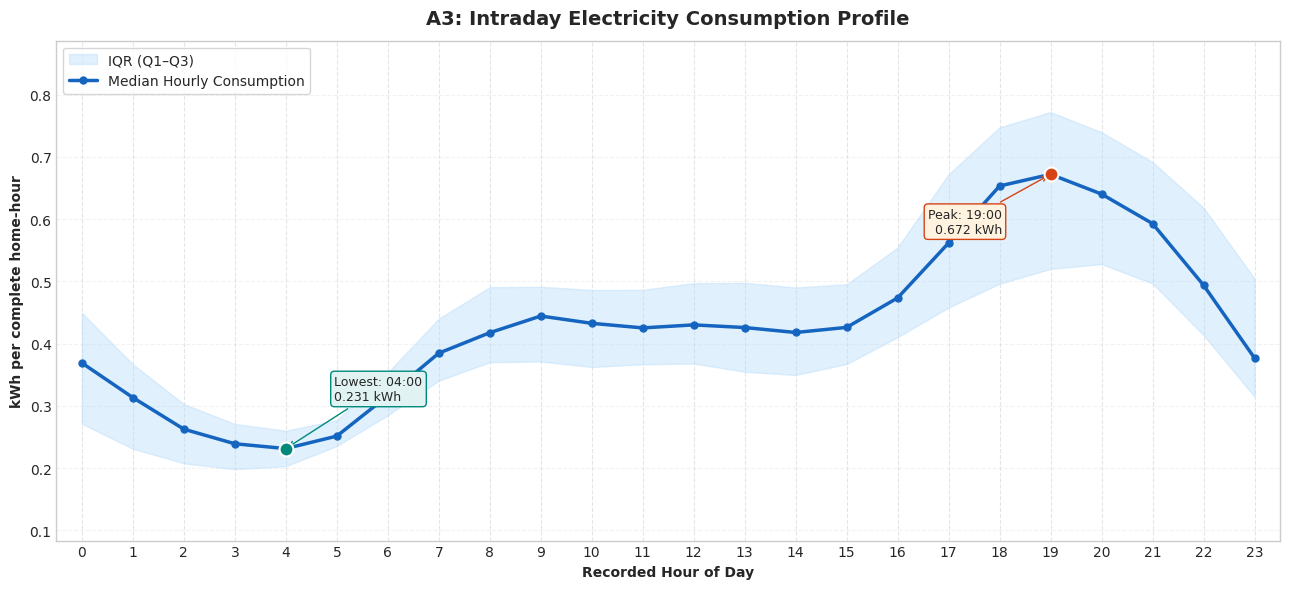

In [20]:

# 1. Keep valid hourly consumption records
df_a3 = df.dropna(
    subset=['avg_kwh_per_complete_home']
).copy()

# 2. Aggregate consumption by recorded hour (0–23)
a3_hourly = (
    df_a3.groupby('hour')['avg_kwh_per_complete_home']
    .agg(
        median='median',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        count='count'
    )
    .reset_index()
    .sort_values('hour')
    .reset_index(drop=True)
)

# 3. Calculate Interquartile Range
a3_hourly['iqr'] = a3_hourly['q75'] - a3_hourly['q25']

# 4. Validate 24-hour profile
assert a3_hourly['hour'].tolist() == list(range(24)), \
    "Missing or unexpected hours in A3!"

assert a3_hourly[['median', 'q25', 'q75']].notna().all().all(), \
    "Missing statistics in A3!"

# 5. Display hourly results
print("=== A3: INTRADAY CONSUMPTION PROFILE ===")

display_cols = [
    'hour', 'median', 'q25', 'q75', 'iqr', 'count'
]

print(
    a3_hourly[display_cols]
    .round(4)
    .to_string(index=False)
)

# 6. Identify peak and trough hours
peak = a3_hourly.loc[a3_hourly['median'].idxmax()]
trough = a3_hourly.loc[a3_hourly['median'].idxmin()]

peak_hour = int(peak['hour'])
trough_hour = int(trough['hour'])

print("\n=== KEY FINDINGS ===")
print(
    f"Peak hour: {peak_hour:02d}:00 "
    f"({peak['median']:.4f} kWh/home-hour)"
)
print(
    f"Lowest consumption hour: {trough_hour:02d}:00 "
    f"({trough['median']:.4f} kWh/home-hour)"
)

if trough['median'] > 0:
    ratio = peak['median'] / trough['median']
    print(f"Peak-to-Trough Ratio: {ratio:.2f}x")
else:
    print("Peak-to-Trough Ratio: Undefined")


# ============================================================
# 7. Visualization — Median + IQR Band
# ============================================================

h = a3_hourly['hour'].to_numpy()
median = a3_hourly['median'].to_numpy()
q25 = a3_hourly['q25'].to_numpy()
q75 = a3_hourly['q75'].to_numpy()

fig, ax = plt.subplots(figsize=(13, 6))

# IQR band
ax.fill_between(
    h, q25, q75,
    color='#BBDEFB',
    alpha=0.45,
    label='IQR (Q1–Q3)',
    zorder=1
)

# Median consumption curve
ax.plot(
    h, median,
    color='#1565C0',
    marker='o',
    markersize=5,
    linewidth=2.5,
    label='Median Hourly Consumption',
    zorder=3
)

# Highlight peak and trough
ax.scatter(
    peak_hour, peak['median'],
    color='#D84315',
    s=100,
    edgecolor='white',
    linewidth=1.5,
    zorder=5
)

ax.scatter(
    trough_hour, trough['median'],
    color='#00897B',
    s=100,
    edgecolor='white',
    linewidth=1.5,
    zorder=5
)

# Dynamic annotations
ax.annotate(
    f"Peak: {peak_hour:02d}:00\n"
    f"{peak['median']:.3f} kWh",
    xy=(peak_hour, peak['median']),
    xytext=(-35 if peak_hour >= 12 else 35, -42),
    textcoords='offset points',
    ha='right' if peak_hour >= 12 else 'left',
    arrowprops=dict(arrowstyle='->', color='#D84315'),
    bbox=dict(boxstyle='round,pad=0.3',
              facecolor='#FFF3E0', edgecolor='#D84315'),
    fontsize=9
)

ax.annotate(
    f"Lowest: {trough_hour:02d}:00\n"
    f"{trough['median']:.3f} kWh",
    xy=(trough_hour, trough['median']),
    xytext=(35 if trough_hour <= 12 else -35, 35),
    textcoords='offset points',
    ha='left' if trough_hour <= 12 else 'right',
    arrowprops=dict(arrowstyle='->', color='#00897B'),
    bbox=dict(boxstyle='round,pad=0.3',
              facecolor='#E0F2F1', edgecolor='#00897B'),
    fontsize=9
)

# Formatting
ax.set_title(
    'A3: Intraday Electricity Consumption Profile',
    fontsize=14,
    fontweight='bold',
    pad=12
)

ax.set_xlabel('Recorded Hour of Day')
ax.set_ylabel('kWh per complete home-hour')

ax.set_xticks(np.arange(0, 24))
ax.set_xlim(-0.5, 23.5)

# Dynamic y-axis to show the full IQR
y_min = q25.min()
y_max = q75.max()
margin = max((y_max - y_min) * 0.20, 0.03)

ax.set_ylim(max(0, y_min - margin), y_max + margin)

ax.grid(axis='y', alpha=0.25)
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


---
## Section 5: A4 — Weekday versus Weekend Profiles

### Business Question
> **How do the shape and timing of typical hourly consumption differ between weekdays and weekends?**

### Playbook Method & Guardrail
* **Primary Metric (Playbook p.11):** Median hourly per-home kWh for Mon–Fri (14,196 hours) vs Sat–Sun (5,667 hours).
* **Quantified Contrasts:** Morning wake-up timing, daytime elevation levels, and evening peak alignment.
* **Guardrail:** Shape differences alone describe empirical associations with calendar days; they do not prove occupancy or working hours.


=== A4: KEY HOURLY CONTRASTS ===
 hour  weekday_kwh  weekend_kwh  diff_kwh  pct_diff
    7        0.419        0.337    -0.082   -19.585
    9        0.424        0.461     0.037     8.632
   12        0.409        0.500     0.091    22.141
   15        0.409        0.489     0.080    19.649
   19        0.670        0.676     0.006     0.934
   22        0.493        0.499     0.005     1.053

Difference = Weekend - Weekday
Positive difference: Weekend consumption is higher.
Negative difference: Weekday consumption is higher.

=== KEY FINDINGS ===
Weekday records: 14,199
Weekend records: 5,664
Weekday peak: 19:00 (0.6700 kWh)
Weekend peak: 19:00 (0.6762 kWh)
Midday difference (11:00–15:00): +21.35%


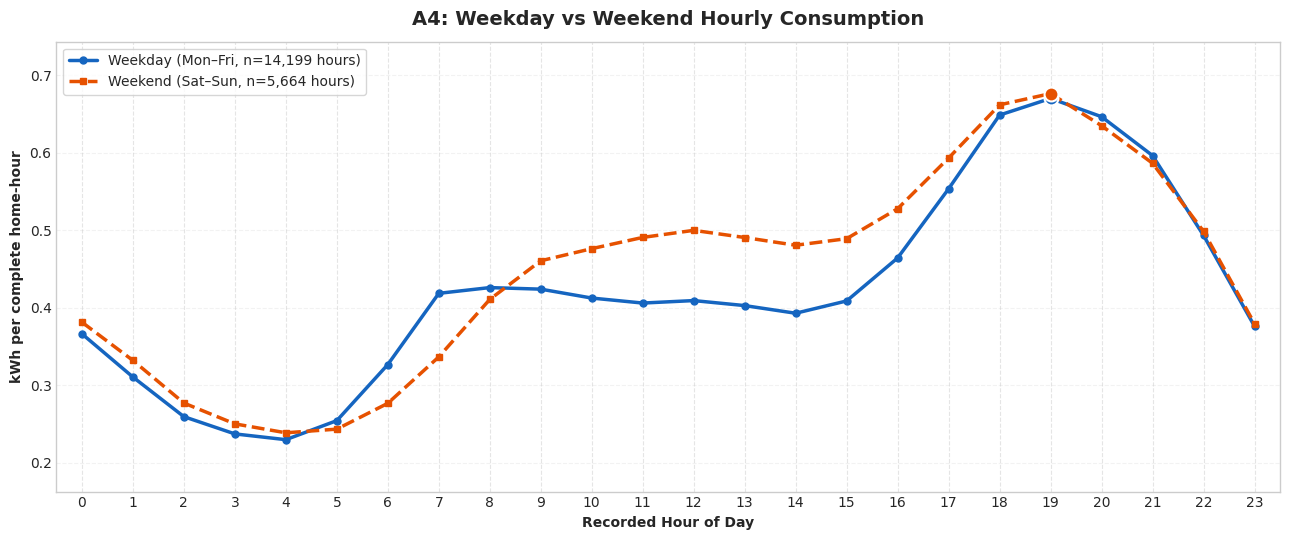

In [21]:

# ============================================================
# A4 — Weekday vs Weekend Consumption Profiles
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Keep valid hourly records
df_a4 = df.dropna(
    subset=['avg_kwh_per_complete_home']
).copy()

# 2. Aggregate by day type and hour
a4_hourly = (
    df_a4.groupby(['is_weekend', 'hour'])
    ['avg_kwh_per_complete_home']
    .agg(
        median='median',
        count='count'
    )
    .reset_index()
)

# 3. Pivot for Weekday vs Weekend comparison
a4_pivot = (
    a4_hourly.pivot(
        index='hour',
        columns='is_weekend',
        values='median'
    )
    .reindex(index=range(24), columns=[False, True])
)

a4_pivot.columns = ['weekday_kwh', 'weekend_kwh']

# 4. Validate both 24-hour profiles
assert a4_pivot.notna().all().all(), \
    "Missing hourly values in Weekday or Weekend profile!"

assert a4_hourly['count'].sum() == len(df_a4), \
    "A4 record count mismatch!"

# 5. Calculate absolute and percentage differences
a4_pivot['diff_kwh'] = (
    a4_pivot['weekend_kwh'] - a4_pivot['weekday_kwh']
)

a4_pivot['pct_diff'] = np.where(
    a4_pivot['weekday_kwh'] > 0,
    100 * a4_pivot['diff_kwh'] / a4_pivot['weekday_kwh'],
    np.nan
)

# 6. Display important hourly contrasts
important_hours = [7, 9, 12, 15, 19, 22]

a4_table = (
    a4_pivot.loc[
        important_hours,
        ['weekday_kwh', 'weekend_kwh', 'diff_kwh', 'pct_diff']
    ]
    .reset_index()
)

print("=== A4: KEY HOURLY CONTRASTS ===")
print(
    a4_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nDifference = Weekend - Weekday")
print("Positive difference: Weekend consumption is higher.")
print("Negative difference: Weekday consumption is higher.")

# 7. Identify peak hours
weekday_peak = a4_pivot['weekday_kwh'].idxmax()
weekend_peak = a4_pivot['weekend_kwh'].idxmax()

# 8. Count eligible records in each group
weekday_count = int((df_a4['is_weekend'] == False).sum())
weekend_count = int((df_a4['is_weekend'] == True).sum())

# 9. Midday comparison (11:00–15:00)
midday = a4_pivot.loc[11:15]

weekday_midday = midday['weekday_kwh'].mean()
weekend_midday = midday['weekend_kwh'].mean()

midday_pct = (
    100 * (weekend_midday - weekday_midday) / weekday_midday
    if weekday_midday > 0 else np.nan
)

print("\n=== KEY FINDINGS ===")

print(f"Weekday records: {weekday_count:,}")
print(f"Weekend records: {weekend_count:,}")

print(
    f"Weekday peak: {weekday_peak:02d}:00 "
    f"({a4_pivot.loc[weekday_peak, 'weekday_kwh']:.4f} kWh)"
)

print(
    f"Weekend peak: {weekend_peak:02d}:00 "
    f"({a4_pivot.loc[weekend_peak, 'weekend_kwh']:.4f} kWh)"
)

print(
    f"Midday difference (11:00–15:00): {midday_pct:+.2f}%"
)

# ============================================================
# 10. Visualization — Single Comparison Plot
# ============================================================

h = a4_pivot.index.to_numpy()

fig, ax = plt.subplots(figsize=(13, 5.5))

# Weekday profile
ax.plot(
    h,
    a4_pivot['weekday_kwh'],
    color='#1565C0',
    marker='o',
    linewidth=2.5,
    markersize=5,
    label=f'Weekday (Mon–Fri, n={weekday_count:,} hours)'
)

# Weekend profile
ax.plot(
    h,
    a4_pivot['weekend_kwh'],
    color='#E65100',
    marker='s',
    linestyle='--',
    linewidth=2.5,
    markersize=5,
    label=f'Weekend (Sat–Sun, n={weekend_count:,} hours)'
)

# Highlight each profile's peak
ax.scatter(
    weekday_peak,
    a4_pivot.loc[weekday_peak, 'weekday_kwh'],
    color='#1565C0',
    s=100,
    edgecolor='white',
    linewidth=1.5,
    zorder=5
)

ax.scatter(
    weekend_peak,
    a4_pivot.loc[weekend_peak, 'weekend_kwh'],
    color='#E65100',
    s=100,
    edgecolor='white',
    linewidth=1.5,
    zorder=5
)

# Formatting
ax.set_title(
    'A4: Weekday vs Weekend Hourly Consumption',
    fontsize=14,
    fontweight='bold',
    pad=12
)

ax.set_xlabel('Recorded Hour of Day')
ax.set_ylabel('kWh per complete home-hour')

ax.set_xticks(np.arange(24))
ax.set_xlim(-0.5, 23.5)

# Dynamic Y-axis
y_min = a4_pivot[['weekday_kwh', 'weekend_kwh']].min().min()
y_max = a4_pivot[['weekday_kwh', 'weekend_kwh']].max().max()
margin = max((y_max - y_min) * 0.15, 0.03)

ax.set_ylim(max(0, y_min - margin), y_max + margin)

ax.grid(axis='y', alpha=0.25)
ax.legend(loc='best', frameon=True)

plt.tight_layout()
plt.show()


---
## Section 6: A5 — Weekday × Hour Heatmap

### Business Question
> **Which combinations of weekday and recorded hour show consistently high typical electricity consumption?**

### Playbook Method & Guardrail
* **Matrix Structure (Playbook p.12):** 7 weekdays (Monday–Sunday) × 24 hours (0–23).
* **Cell Metric:** Median hourly per-home kWh (`avg_kwh_per_complete_home`).
* **Guardrail:** Must use the median of normalized per-home values, never the sum of all homes with differing participation.


=== A5: TOP 5 HIGHEST CONSUMPTION CELLS ===
 day_name  hour  median_kwh
   Monday    19      0.6853
   Sunday    18      0.6850
   Sunday    19      0.6829
  Tuesday    19      0.6746
Wednesday    19      0.6701

=== A5: TOP 5 LOWEST CONSUMPTION CELLS ===
 day_name  hour  median_kwh
Wednesday     4      0.2278
 Thursday     4      0.2285
   Monday     4      0.2302
  Tuesday     4      0.2307
   Friday     4      0.2313


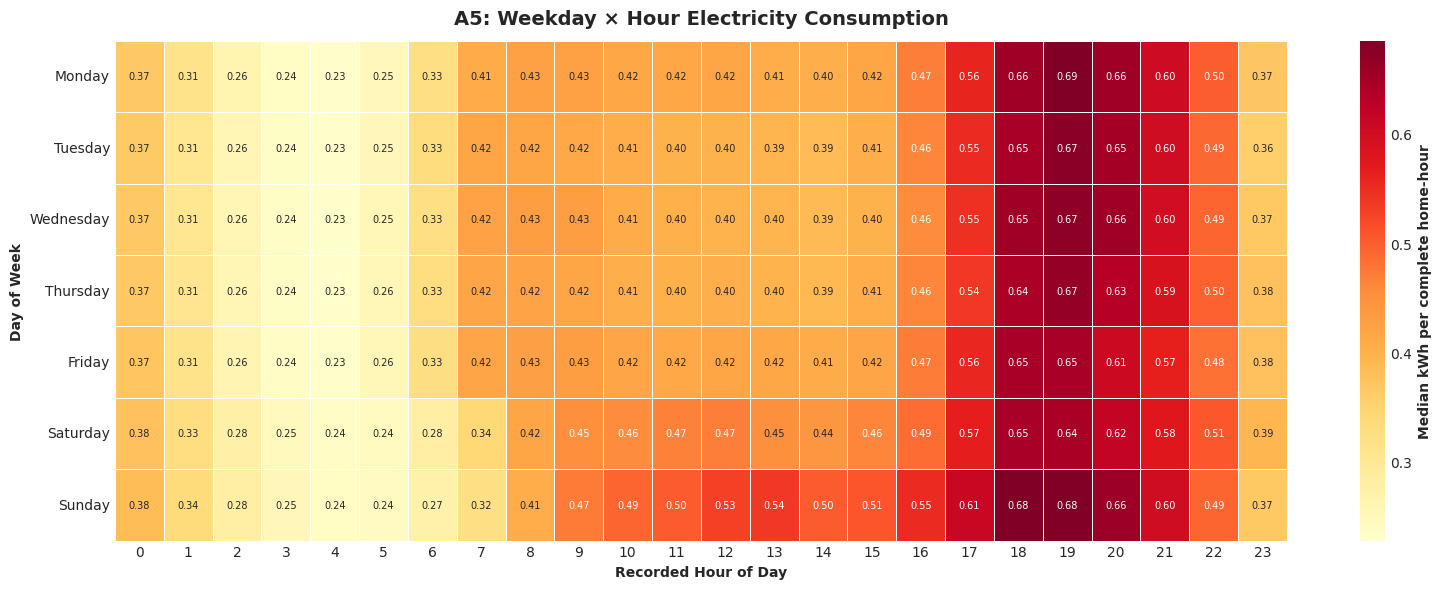

In [22]:


# 1. Keep valid hourly consumption records
df_a5 = df.dropna(
    subset=['avg_kwh_per_complete_home']
).copy()

# 2. Define weekday order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# 3. Calculate median consumption by weekday and hour
a5_matrix = (
    df_a5.groupby(['day_name', 'hour'])
    ['avg_kwh_per_complete_home']
    .median()
    .unstack('hour')
    .reindex(index=day_order, columns=range(24))
)

# 4. Validate 7 × 24 matrix
assert a5_matrix.shape == (7, 24), \
    "A5 matrix must have 7 days and 24 hours!"

assert a5_matrix.notna().all().all(), \
    "Missing values in A5 weekday-hour matrix!"

# 5. Convert matrix to a table for ranking
a5_cells = (
    a5_matrix
    .stack()
    .rename('median_kwh')
    .reset_index()
)

# 6. Identify highest and lowest consumption cells
top5_cells = a5_cells.nlargest(5, 'median_kwh')
bottom5_cells = a5_cells.nsmallest(5, 'median_kwh')

print("=== A5: TOP 5 HIGHEST CONSUMPTION CELLS ===")
print(
    top5_cells.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n=== A5: TOP 5 LOWEST CONSUMPTION CELLS ===")
print(
    bottom5_cells.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ============================================================
# 7. Visualization — 7 × 24 Heatmap
# ============================================================

fig, ax = plt.subplots(figsize=(16, 6))

sns.heatmap(
    a5_matrix,
    cmap='YlOrRd',
    annot=True,
    fmt='.2f',
    annot_kws={'fontsize': 7},
    linewidths=0.4,
    linecolor='white',
    cbar_kws={
        'label': 'Median kWh per complete home-hour'
    },
    ax=ax
)

ax.set_title(
    'A5: Weekday × Hour Electricity Consumption',
    fontsize=14,
    fontweight='bold',
    pad=12
)

ax.set_xlabel('Recorded Hour of Day')
ax.set_ylabel('Day of Week')

ax.set_xticklabels(range(24), rotation=0)
ax.set_yticklabels(day_order, rotation=0)

plt.tight_layout()
plt.show()


---
## Section 7: A6 — Seasonal Demand Profile

### Business Question
> **Does the timing or amplitude of the usual consumption peak differ between meteorological seasons?**

### Playbook Method & Guardrail
* **Seasonal Definitions (Playbook p.09 & 12):** Fixed meteorological seasons:
  * **Winter:** December, January, February
  * **Spring:** March, April, May
  * **Summer:** June, July, August
  * **Autumn:** September, October, November
* **Metric:** Median hourly per-home kWh by season and hour-of-day (4 × 24-hour curves).
* **Guardrail:** Partial years (Nov 2011, Jan–Feb 2014) and customer growth can influence seasonal averages; compare profiles on identical scales.


=== A6: SEASONAL PROFILE SUMMARY ===
Season  Hours Peak Hour  Peak kWh Trough Hour  Trough kWh  Amplitude kWh  Peak/Trough Ratio
Winter   6480     19:00    0.7835       04:00      0.2607         0.5228             3.0050
Spring   4416     19:00    0.6208       04:00      0.2463         0.3745             2.5207
Summer   4416     20:00    0.4807       03:00      0.1948         0.2858             2.4671
Autumn   4551     18:00    0.6633       03:00      0.2079         0.4554             3.1910

=== KEY FINDINGS ===
Highest peak consumption: Winter
Lowest peak consumption: Summer
Largest daily amplitude: Winter


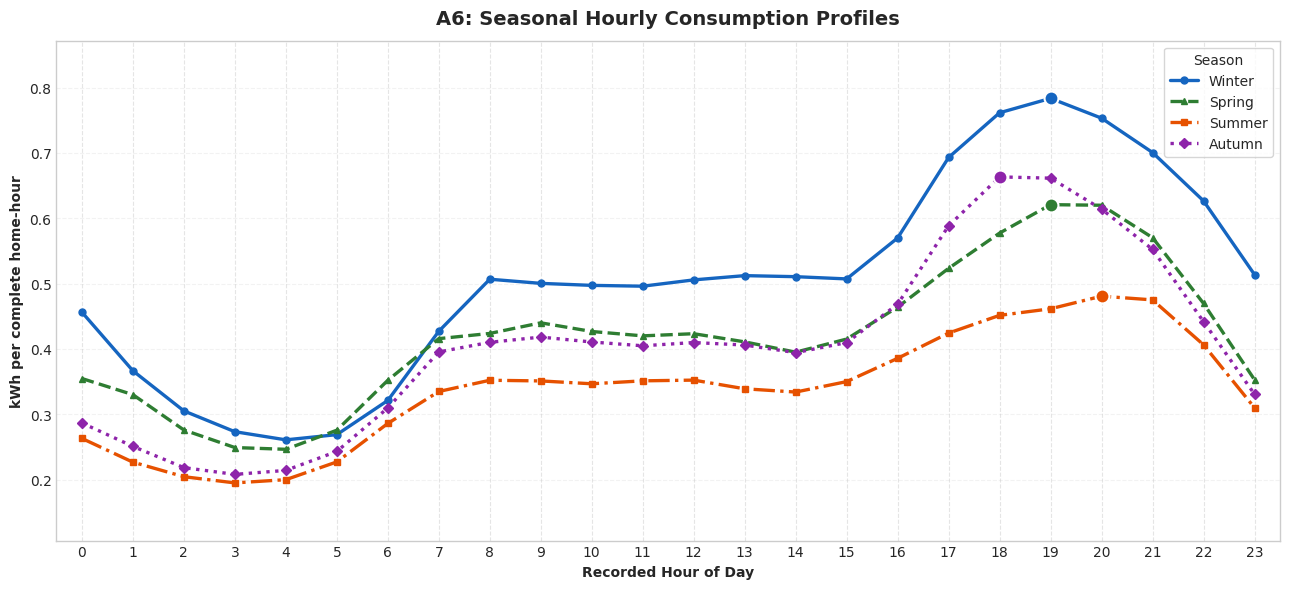

In [27]:

# ============================================================
# A6 — Seasonal Demand Profile
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Keep valid hourly records
df_a6 = df.dropna(
    subset=['avg_kwh_per_complete_home']
).copy()

# 2. Define meteorological season order
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']

# 3. Validate input data
assert df_a6[['season', 'hour']].notna().all().all(), \
    "Missing season or hour values!"

assert df_a6['season'].isin(season_order).all(), \
    "Unexpected season labels!"

assert df_a6['hour'].isin(range(24)).all(), \
    "Invalid recorded hours!"

# 4. Calculate median consumption by season and hour
a6_season = (
    df_a6.groupby(['season', 'hour'], observed=True)
    ['avg_kwh_per_complete_home']
    .median()
    .unstack('season')
    .reindex(index=range(24), columns=season_order)
)

# 5. Validate seasonal profiles
assert a6_season.shape == (24, 4), \
    "Expected 24 hours and 4 seasons!"

assert a6_season.notna().all().all(), \
    "Missing values in seasonal profiles!"

# 6. Count eligible hourly records per season
season_counts = (
    df_a6.groupby('season', observed=True)
    .size()
    .reindex(season_order, fill_value=0)
)

assert season_counts.sum() == len(df_a6), \
    "Seasonal record count mismatch!"

# ============================================================
# 7. Seasonal Summary
# ============================================================

season_summary = []

for season in season_order:
    profile = a6_season[season]

    peak_hour = int(profile.idxmax())
    trough_hour = int(profile.idxmin())

    peak_kwh = profile.max()
    trough_kwh = profile.min()

    amplitude = peak_kwh - trough_kwh

    amplitude_ratio = (
        peak_kwh / trough_kwh
        if trough_kwh > 0 else np.nan
    )

    season_summary.append({
        'Season': season,
        'Hours': int(season_counts[season]),
        'Peak Hour': f'{peak_hour:02d}:00',
        'Peak kWh': peak_kwh,
        'Trough Hour': f'{trough_hour:02d}:00',
        'Trough kWh': trough_kwh,
        'Amplitude kWh': amplitude,
        'Peak/Trough Ratio': amplitude_ratio
    })

a6_summary = pd.DataFrame(season_summary)

print("=== A6: SEASONAL PROFILE SUMMARY ===")
print(
    a6_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# 8. Key findings
highest_peak = a6_summary.loc[
    a6_summary['Peak kWh'].idxmax(), 'Season'
]

lowest_peak = a6_summary.loc[
    a6_summary['Peak kWh'].idxmin(), 'Season'
]

largest_amplitude = a6_summary.loc[
    a6_summary['Amplitude kWh'].idxmax(), 'Season'
]

print("\n=== KEY FINDINGS ===")
print(f"Highest peak consumption: {highest_peak}")
print(f"Lowest peak consumption: {lowest_peak}")
print(f"Largest daily amplitude: {largest_amplitude}")

# ============================================================
# 9. Visualization — Four Seasonal Profiles
# ============================================================

colors = {
    'Winter': '#1565C0',
    'Spring': '#2E7D32',
    'Summer': '#E65100',
    'Autumn': '#8E24AA'
}

styles = {
    'Winter': '-',
    'Spring': '--',
    'Summer': '-.',
    'Autumn': ':'
}

markers = {
    'Winter': 'o',
    'Spring': '^',
    'Summer': 's',
    'Autumn': 'D'
}

fig, ax = plt.subplots(figsize=(13, 6))

hours = a6_season.index.to_numpy()

for season in season_order:

    profile = a6_season[season]

    ax.plot(
        hours,
        profile,
        color=colors[season],
        linestyle=styles[season],
        marker=markers[season],
        linewidth=2.4,
        markersize=5,
        label=season
    )

    # Highlight seasonal peak
    peak_hour = int(profile.idxmax())

    ax.scatter(
        peak_hour,
        profile.loc[peak_hour],
        color=colors[season],
        s=100,
        edgecolor='white',
        linewidth=1.5,
        zorder=5
    )

# 10. Formatting
ax.set_title(
    'A6: Seasonal Hourly Consumption Profiles',
    fontsize=14,
    fontweight='bold',
    pad=12
)

ax.set_xlabel('Recorded Hour of Day')
ax.set_ylabel('kWh per complete home-hour')

ax.set_xticks(np.arange(24))
ax.set_xlim(-0.5, 23.5)

# Dynamic Y-axis shared by all four profiles
y_min = a6_season.min().min()
y_max = a6_season.max().max()

margin = max((y_max - y_min) * 0.15, 0.03)

ax.set_ylim(
    max(0, y_min - margin),
    y_max + margin
)

ax.grid(axis='y', alpha=0.25)
ax.legend(title='Season', loc='best', frameon=True)

plt.tight_layout()
plt.show()


---
## Section 8: A8 — Autocorrelation & Lag Structure Diagnostics

### Business Question
> **Does a suitably prepared hourly series display dependence at daily (lag 24) or weekly (lag 168) intervals?**

### Playbook Method & Guardrail
* **Grid Validation (Playbook p.13):** Check uniqueness and 1-hour grid continuity; inspect missingness.
* **Protocol on Missingness:** Never feed missing hours to ACF as zero without justification. As established in Section 0, the dataset forms a complete 19,864-hour grid with exactly one boundary null at index 19,863 (2014-02-28 00:00:00). We exclude this terminal record, retaining 19,863 contiguous hours.
* **Stationarity & Differencing:** High persistence in the raw series can obscure cyclical periodicity. We evaluate both the raw level ACF and the 24-hour seasonally differenced series ($\Delta_{24} E_t = E_t - E_{t-24}$) to rigorously isolate daily vs weekly dependence.


=== A8: TIME SERIES VALIDATION ===
Original hours: 19,864
Eligible hours: 19,863
Start: 2011-11-23 09:00:00
End: 2014-02-27 23:00:00
Hourly continuity: Passed
Internal missing values: 0

=== A8: KEY LAG CORRELATIONS ===
 Lag   Description  Raw ACF  Diff24 ACF
   1 Previous hour   0.9359      0.8400
   2       2 hours   0.7835      0.6204
  12      12 hours  -0.0270      0.1003
  23      23 hours   0.9047     -0.1252
  24         1 day   0.9644     -0.1429
  25      25 hours   0.9076     -0.0829
  48        2 days   0.9395     -0.2177
  72        3 days   0.9294     -0.0784
  96        4 days   0.9245     -0.0774
 120        5 days   0.9252     -0.2047
 144        6 days   0.9398      0.0206
 167     167 hours   0.8931      0.4512
 168        1 week   0.9531      0.5178
 169     169 hours   0.8952      0.4583
 336       2 weeks   0.9252      0.5326

=== IMPORTANT LAGS ===
Lag  24: Raw = +0.9644 | Diff24 = -0.1429
Lag 168: Raw = +0.9531 | Diff24 = +0.5178
Lag 336: Raw = +0.9252 | Diff24 

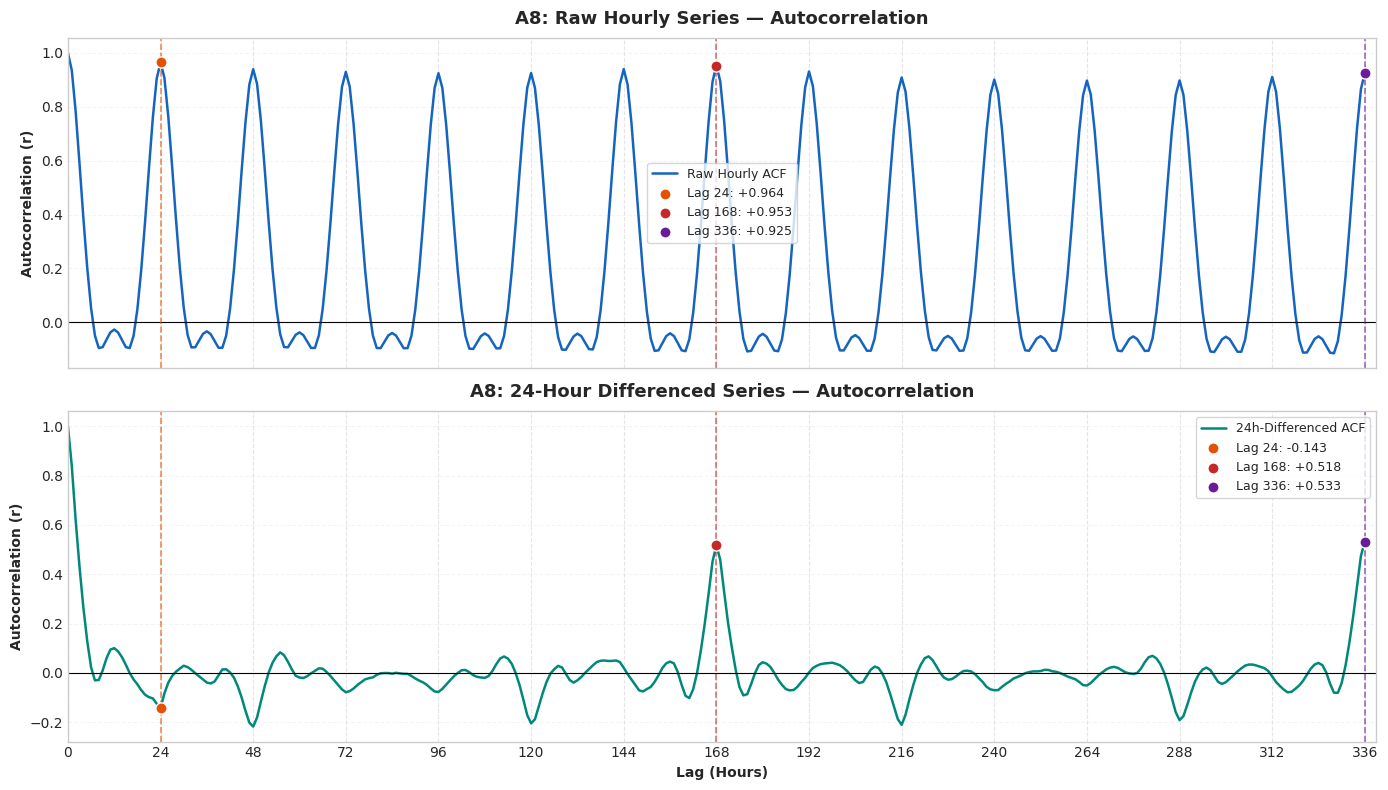

In [28]:

# ============================================================
# A8 — Autocorrelation & Lag Structure Diagnostics
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# ============================================================
# 1. Prepare and validate hourly time series
# ============================================================

df_a8 = df[
    ['hour_start', 'avg_kwh_per_complete_home']
].copy()

df_a8['hour_start'] = pd.to_datetime(df_a8['hour_start'])

df_a8 = (
    df_a8.sort_values('hour_start')
    .reset_index(drop=True)
)

# Check expected dataset size
assert len(df_a8) == 19864, \
    "Unexpected number of hourly records!"

# Check timestamps
assert df_a8['hour_start'].notna().all(), \
    "Missing timestamps!"

assert df_a8['hour_start'].is_unique, \
    "Duplicate hourly timestamps found!"

# Check continuous 1-hour grid
time_diffs = df_a8['hour_start'].diff().iloc[1:]

assert (time_diffs == pd.Timedelta(hours=1)).all(), \
    "Hourly grid is not continuous!"

# Verify exactly one missing value at the final record
missing_positions = np.flatnonzero(
    df_a8['avg_kwh_per_complete_home'].isna().to_numpy()
)

assert missing_positions.tolist() == [len(df_a8) - 1], \
    "Expected exactly one terminal missing consumption value!"

# Exclude the terminal null
s_clean = (
    df_a8['avg_kwh_per_complete_home']
    .iloc[:-1]
    .astype(float)
    .reset_index(drop=True)
)

assert np.isfinite(s_clean.to_numpy()).all(), \
    "Invalid values remain in ACF input!"

print("=== A8: TIME SERIES VALIDATION ===")
print(f"Original hours: {len(df_a8):,}")
print(f"Eligible hours: {len(s_clean):,}")
print(f"Start: {df_a8['hour_start'].iloc[0]}")
print(f"End: {df_a8['hour_start'].iloc[-2]}")
print("Hourly continuity: Passed")
print("Internal missing values: 0")


# ============================================================
# 2. Raw Series ACF
# ============================================================

max_lags = 336

acf_raw = acf(
    s_clean,
    nlags=max_lags,
    fft=True
)


# ============================================================
# 3. 24-Hour Seasonal Differencing
# ============================================================

s_diff24 = s_clean.diff(24).dropna()

assert len(s_diff24) > max_lags, \
    "Not enough observations for differenced ACF!"

acf_diff24 = acf(
    s_diff24,
    nlags=max_lags,
    fft=True
)


# ============================================================
# 4. Key Lag Statistics
# ============================================================

key_lags = [
    1, 2, 12, 23, 24, 25,
    48, 72, 96, 120, 144,
    167, 168, 169, 336
]

lag_descriptions = {
    1: 'Previous hour',
    2: '2 hours',
    12: '12 hours',
    23: '23 hours',
    24: '1 day',
    25: '25 hours',
    48: '2 days',
    72: '3 days',
    96: '4 days',
    120: '5 days',
    144: '6 days',
    167: '167 hours',
    168: '1 week',
    169: '169 hours',
    336: '2 weeks'
}

acf_table = pd.DataFrame({
    'Lag': key_lags,
    'Description': [
        lag_descriptions[k] for k in key_lags
    ],
    'Raw ACF': [
        acf_raw[k] for k in key_lags
    ],
    'Diff24 ACF': [
        acf_diff24[k] for k in key_lags
    ]
})

print("\n=== A8: KEY LAG CORRELATIONS ===")
print(
    acf_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n=== IMPORTANT LAGS ===")

for k in [24, 168, 336]:
    print(
        f"Lag {k:3d}: "
        f"Raw = {acf_raw[k]:+.4f} | "
        f"Diff24 = {acf_diff24[k]:+.4f}"
    )


# ============================================================
# 5. Visualization — Two ACF Panels
# ============================================================

lags = np.arange(max_lags + 1)

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# Panel 1 — Raw ACF
ax1.plot(
    lags,
    acf_raw,
    color='#1565C0',
    linewidth=1.8,
    label='Raw Hourly ACF'
)

ax1.axhline(0, color='black', linewidth=0.8)

# Panel 2 — Differenced ACF
ax2.plot(
    lags,
    acf_diff24,
    color='#00897B',
    linewidth=1.8,
    label='24h-Differenced ACF'
)

ax2.axhline(0, color='black', linewidth=0.8)

# Highlight theoretical lag positions
highlight_lags = {
    24: '#E65100',
    168: '#C62828',
    336: '#6A1B9A'
}

for ax, values in [
    (ax1, acf_raw),
    (ax2, acf_diff24)
]:
    for lag, color in highlight_lags.items():

        ax.axvline(
            lag,
            color=color,
            linestyle='--',
            linewidth=1.2,
            alpha=0.65
        )

        ax.scatter(
            lag,
            values[lag],
            color=color,
            s=65,
            edgecolor='white',
            linewidth=1,
            zorder=5,
            label=f'Lag {lag}: {values[lag]:+.3f}'
        )

    ax.set_ylabel('Autocorrelation (r)')
    ax.grid(axis='y', alpha=0.2)
    ax.legend(loc='best', fontsize=9, frameon=True)

# Titles
ax1.set_title(
    'A8: Raw Hourly Series — Autocorrelation',
    fontsize=13,
    fontweight='bold',
    pad=10
)

ax2.set_title(
    'A8: 24-Hour Differenced Series — Autocorrelation',
    fontsize=13,
    fontweight='bold',
    pad=10
)

# Shared X-axis
ax2.set_xlabel('Lag (Hours)')
ax2.set_xticks(np.arange(0, max_lags + 1, 24))
ax2.set_xlim(0, max_lags + 3)

plt.tight_layout()
plt.show()
